#  Elastostatics Code using Quadratic Elements (ELQUABE)

A FORTRAN code for isotropic elasticity

The program allows for the traction values at both sides of the nodes connecting two elements to be different. For each particular $x_1$ or $x_2$ direction, (i) when both tractions are prescribed as different at both sides of the node the displacement is the only unknown; (ii) when the displacement and one traction is prescribed one on each side the other traction is the unknown and (iii) if only the displacement is prescribed, one value of the traction is the only unknown and this will be the same at both sides of the node.

# Mount Google Drive

# Download `quadpleh` from `Github`

In [29]:
!git clone https://github.com/e-albuquerque/BEM2D-Elastostatics-ELQUABE.git

Cloning into 'BEM2D-Elastostatics-ELQUABE'...
remote: Enumerating objects: 99, done.
remote: Counting objects: 100% (99/99), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 99 (delta 48), reused 98 (delta 47), pack-reused 0 (from 0)
Receiving objects: 100% (99/99), 1.66 MiB | 25.38 MiB/s, done.
Resolving deltas: 100% (48/48), done.


In [30]:
ls

assembly_mod.f90              eq12cb.dat    posproc.py
BEM2D-Elastostatics-ELQUABE/  eq12cb.out    preproc.py
build.bat                     geometry.png  README.md
data_mod.f90                  io_mod.f90    resultado_elquabe.vtk
data_mod.mod                  io_mod.mod    result_plot.png
data_mod.o                    io_mod.o      Run_elquabe_on_Colab.ipynb
displacement_map.png          main.f90      solver_mod.f90
dpbou.dat                     Makefile      stbou.dat
dpint.dat                     placa.geo     stint.dat
elquabe.for                   placa.msh     von_mises_map.png


In [31]:
cd BEM2D-Elastostatics-ELQUABE/

/content/BEM2D-Elastostatics-ELQUABE/BEM2D-Elastostatics-ELQUABE/BEM2D-Elastostatics-ELQUABE


In [32]:
ls

assembly_mod.f90      geometry.png  resultado_elquabe.vtk
build.bat             io_mod.f90    result_plot.png
data_mod.f90          main.f90      Run_elquabe_on_Colab.ipynb
displacement_map.png  Makefile      solver_mod.f90
dpbou.dat             placa.geo     stbou.dat
dpint.dat             placa.msh     stint.dat
elquabe.for           posproc.py    von_mises_map.png
eq12cb.dat            preproc.py
eq12cb.out            README.md


# Compile the code ```elquabe.for```

In [33]:
!make

gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c data_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c io_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c assembly_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c solver_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c main.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -o elquabe_modern.exe data_mod.o io_mod.o assembly_mod.o solver_mod.o main.o -llapack -lblas


In [34]:
ls

assembly_mod.f90      eq12cb.dat    preproc.py
assembly_mod.mod      eq12cb.out    README.md
assembly_mod.o        geometry.png  resultado_elquabe.vtk
build.bat             io_mod.f90    result_plot.png
data_mod.f90          io_mod.mod    Run_elquabe_on_Colab.ipynb
data_mod.mod          io_mod.o      solver_mod.f90
data_mod.o            main.f90      solver_mod.mod
displacement_map.png  main.o        solver_mod.o
dpbou.dat             Makefile      stbou.dat
dpint.dat             placa.geo     stint.dat
elquabe.for           placa.msh     von_mises_map.png
elquabe_modern.exe*   posproc.py


# Install `gmsh`

In [35]:
!apt-get update
!apt-get install gmsh
!python -m pip install gmsh

Hit:1 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:2 https://cli.github.com/packages stable InRelease
Hit:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Ign:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Ign:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Ign:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Err:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
  503  Service Unavailable [IP: 185.125.189.187 443]
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list 

# Install `meshio`

In [36]:
!pip install meshio[all]

# Gmsh geometry file (`.geo`)

In [37]:
%%writefile placa.geo
ref=1.;
L=1.;
W=1.;
Point(1) = {0, 0, 0, ref};
Point(2) = {L, 0, 0, ref};
Point(3) = {L, W, 0, ref};
Point(4) = {0, W, 0, ref};
Line(1) = {1, 2};
Line(2) = {2, 3};
Line(3) = {3, 4};
Line(4) = {4, 1};
Line Loop(1) = {1, 2, 3, 4};
Plane Surface(1) = {1};
Physical Curve("botton") = {1};
Physical Curve("right") = {2};
Physical Curve("top") = {3};
Physical Curve("left") = {4};
Physical Surface("surf1") = {1};

Overwriting placa.geo


# Generate mesh file (`.msh`) using Gmsh

In [38]:
!gmsh -2  placa.geo -o placa.msh  -order 2

Info    : Running '/usr/local/bin/gmsh -2 placa.geo -o placa.msh -order 2' [Gmsh 4.15.2, 1 node, max. 1 thread]
Info    : Started on Wed Oct 21 20:31:17 2026
Info    : Reading 'placa.geo'...
Info    : Done reading 'placa.geo'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.00078614s, CPU 0.000462s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.000386329s, CPU 0.00037s)
Info    : Meshing order 2 (curvilinear on)...
Info    : [  0%] Meshing curve 1 order 2
Info    : [ 30%] Meshing curve 2 order 2
Info    : [ 50%] Meshing curve 3 order 2
Info    : [ 70%] Meshing curve 4 order 2
Info    : [ 90%] Meshing surface 1 order 2
Info    : Surface mesh: worst distortion = 1 (0 elements in ]0, 0.2]); worst gamma = 0.828427
Info    : Done meshing order 2 (Wall 0.000101

# Input data

In [44]:
%%writefile input_data.py
import numpy as np
def input_data():
    """
    Defines input parameters for the 2D Elastostatic Boundary Element Method (BEM)
    simulation using quadratic boundary elements (ELQUABE).

    Returns:
        dict: Dictionary containing:
            * title (str): Problem description title
            * bound_cond (dict): Boundary conditions for each physical edge
              (type: 0 = prescribed displacement, 1 = prescribed traction)
            * E (float): Young's modulus
            * nu (float): Poisson's ratio
            * file_name (str): Base name of the Gmsh .msh file
    """
    bound_cond = {
        'botton': {'type_x': 0, 'value_x': 0.0, 'type_y': 0, 'value_y': 0.0},
        'right':  {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 0.0},
        'top':    {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 1.0},
        'left':   {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 0.0},
    }
    E = 1.0
    nu = 0.0
    file_name = 'placa'
    title = 'SQUARE PLATE UNDER UNIAXIAL STATIC TRACTION (4 QUADRATIC ELEMENTS)'

    return {
        'title': title,
        'bound_cond': bound_cond,
        'E': E,
        'nu': nu,
        'file_name': file_name,
    }

Writing input_data.py


# Run `preproc.py`

In [46]:
!python preproc.py


Geometry plot saved to 'geometry.png'.
Input file 'eq12cb.dat' generated successfully.


# Run `elquabe_modern.exe`

In [47]:
!./elquabe_modern.exe

In [48]:
ls

assembly_mod.f90      eq12cb.out     __pycache__/
assembly_mod.mod      geometry.png   README.md
assembly_mod.o        input_data.py  resultado_elquabe.vtk
build.bat             io_mod.f90     result_plot.png
data_mod.f90          io_mod.mod     Run_elquabe_on_Colab.ipynb
data_mod.mod          io_mod.o       solver_mod.f90
data_mod.o            main.f90       solver_mod.mod
displacement_map.png  main.o         solver_mod.o
dpbou.dat             Makefile       stbou.dat
dpint.dat             placa.geo      stint.dat
elquabe.for           placa.msh      von_mises_map.png
elquabe_modern.exe*   posproc.py
eq12cb.dat            preproc.py


# Run `posproc.py`

In [50]:
!python posproc.py

ELQUABE 2D ELASTOSTATIC VALIDATION SUMMARY
Relative L2 Error in Vertical Displacement u_y      : 1.0063e-04
Relative L2 Error in von Mises Stress (All Nodes)   : 8.8183e-03
------------------------------------------------------------------------------
Boundary Nodes von Mises Stress (x, y, sigma_x, tau_xy, sigma_y, sigma_vM):
  Node 1 (0.00, 0.00): sx= 0.00e+00, txy= 1.60e-08, sy=1.000000, vM=1.000000
  Node 2 (0.50, 0.00): sx= 0.00e+00, txy= 6.74e-12, sy=1.000000, vM=1.000000
  Node 3 (1.00, 0.00): sx= 0.00e+00, txy=-1.60e-08, sy=1.000000, vM=1.000000
  Node 4 (1.00, 0.50): sx= 0.00e+00, txy= 0.00e+00, sy=1.000000, vM=1.000000
  Node 5 (1.00, 1.00): sx=-1.80e-08, txy= 0.00e+00, sy=1.000000, vM=1.000000
  Node 6 (0.50, 1.00): sx=-3.61e-08, txy= 0.00e+00, sy=1.000000, vM=1.000000
  Node 7 (0.00, 1.00): sx=-1.81e-08, txy= 0.00e+00, sy=1.000000, vM=1.000000
  Node 8 (0.00, 0.50): sx= 0.00e+00, txy= 0.00e+00, sy=1.000000, vM=1.000000
--------------------------------------------------------

# Show von Mises equivalent stress

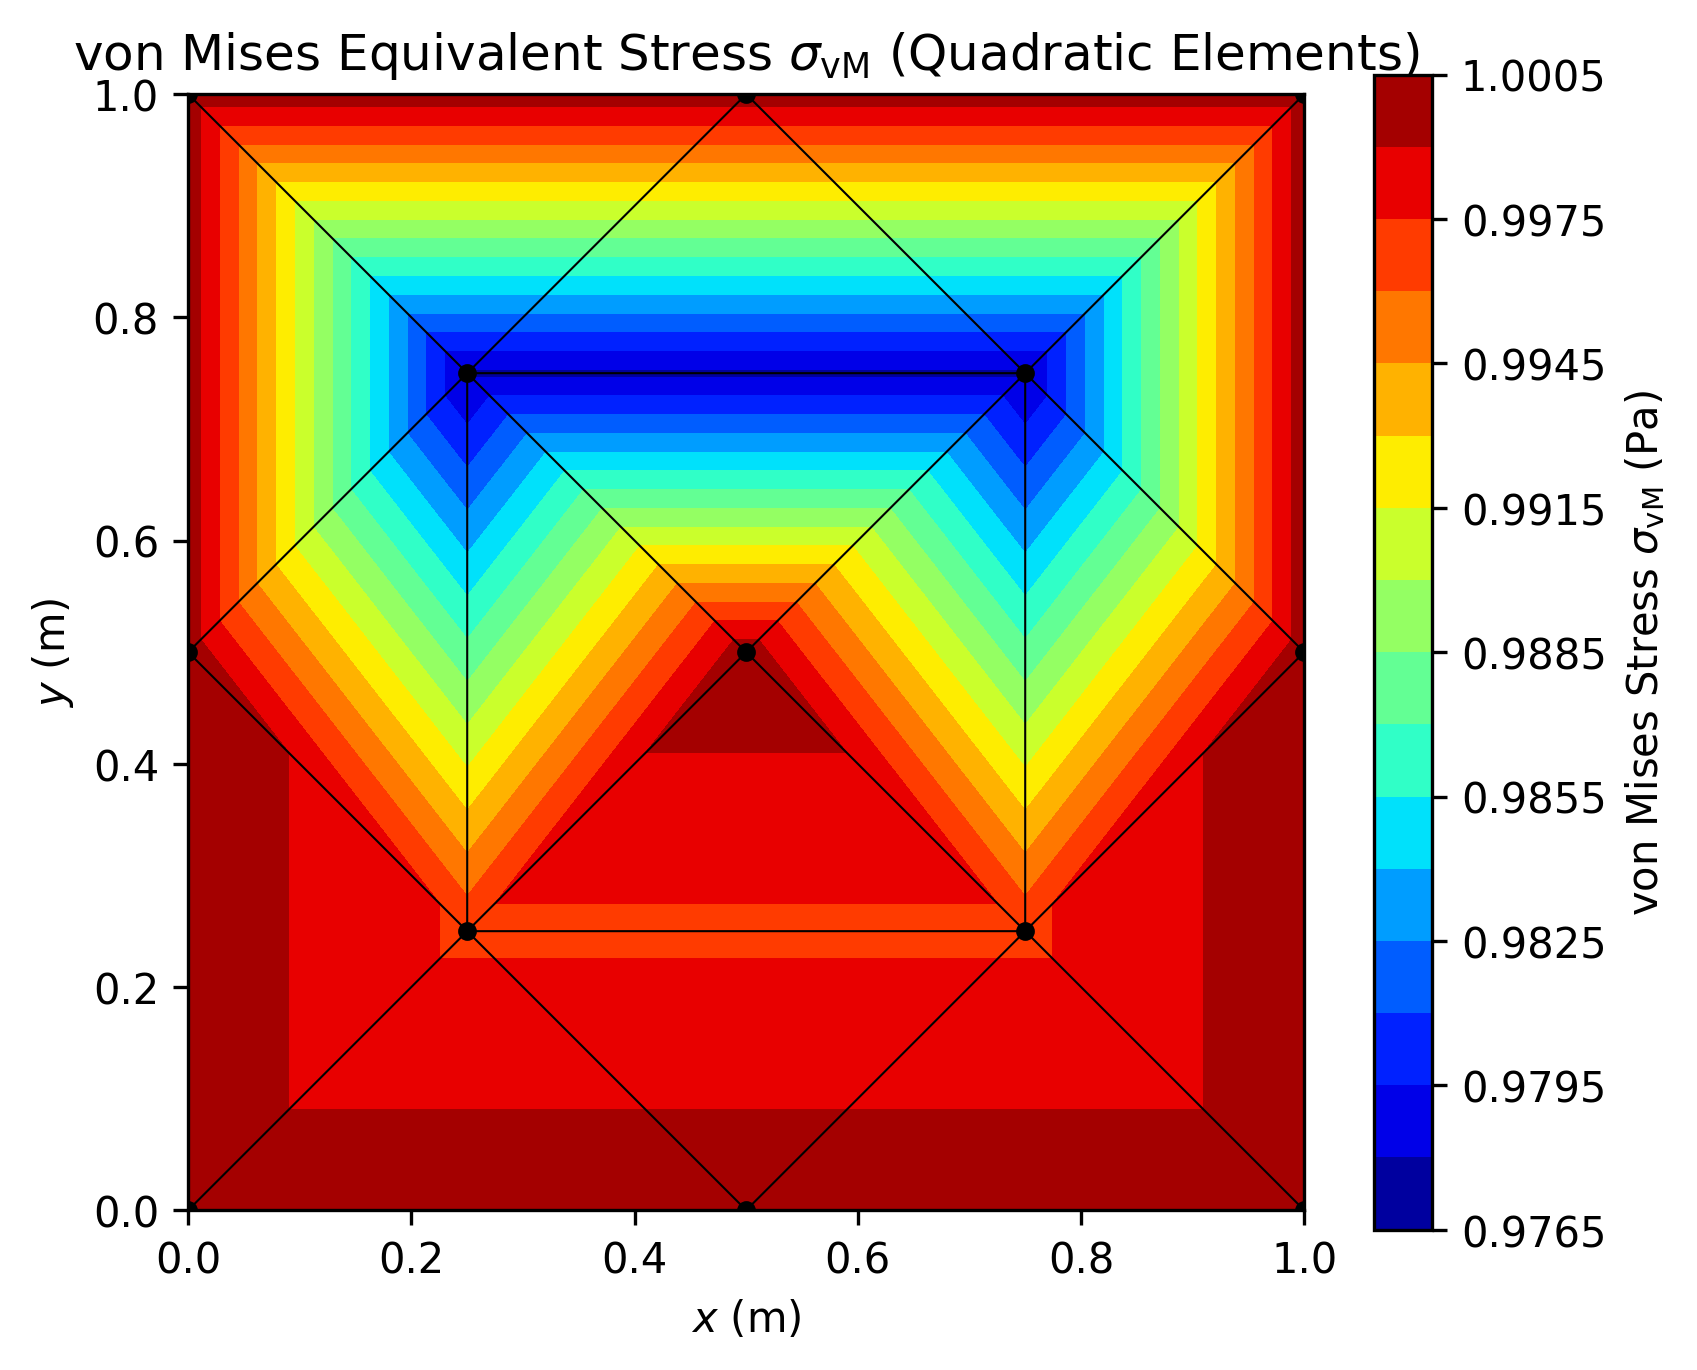

In [52]:
from IPython.display import Image
Image('von_mises_map.png', width=500)